# 地磁场测量实验 —— 亥姆霍兹线圈轴向磁场分布的测量

**原始数据**：表 11-3，传感器沿线圈轴线位置 $x$（以线圈半径 $R$ 为单位，$-0.5R\sim0.5R$，每 $0.1R$）
与输出电压 $U_x$。本实验条件下线圈中心的标准磁感应强度 $B_0=4\ \mathrm{Gs}$。

**填写表格所用的两个来源**

1. **$B_x$ 理论值**：取另一张表中按亥姆霍兹公式算好的 $B_x/B_0$ 比值行
   （0.946, 0.975, 0.992, 0.998, 1.000, …），乘以 $B_0=4$ Gs。
   该比值对应的一对同轴线圈（半径 $R$、间距 $R$）轴向场为
   $$\frac{B(x)}{B(0)}=
   \frac{\left[1+\left(\frac{x}{R}-\frac12\right)^2\right]^{-3/2}+\left[1+\left(\frac{x}{R}+\frac12\right)^2\right]^{-3/2}}
        {2\left(1+\frac14\right)^{-3/2}} .$$
2. **$B_x$ 测量值**：用表 11-1 拟合出的 $U$–$B$ 线性关系 $U=a+bB$ 反解，
   $$B_x=\frac{U_x-a}{b},\qquad a=0.0065\ \mathrm{V},\ b=0.2509\ \mathrm{V/Gs}.$$

**相对误差**：$\dfrac{|B_x^{测}-B_x^{理}|}{B_x^{理}}\times100\%$。

**作图**：以位置 $x/R$ 为横轴、$B_x$ 为纵轴，实测点与理论曲线同图比较，
据此讨论亥姆霍兹线圈轴向磁场的分布特点。


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.font_manager as fm

# ---------- 字体：英文用 Times New Roman，中文逐字回退到宋体 ----------
_installed = {f.name for f in fm.fontManager.ttflist}
_cjk_candidates = ['SimSun', 'STSong', 'Songti SC', 'Noto Serif SC',
                   'Source Han Serif SC', 'SimHei', 'Microsoft YaHei']
CJK_FONT = next((f for f in _cjk_candidates if f in _installed), 'DejaVu Sans')

rcParams['font.family']        = ['Times New Roman', CJK_FONT, 'DejaVu Sans']
rcParams['mathtext.fontset']   = 'stix'
rcParams['axes.unicode_minus'] = False
rcParams['figure.facecolor']   = 'white'
rcParams['savefig.facecolor']  = 'white'

pd.set_option('display.unicode.east_asian_width', True)

# ---------- 原始数据（表 11-3） ----------
x_R   = np.array([-0.5, -0.4, -0.3, -0.2, -0.1, 0.0,
                   0.1,  0.2,  0.3,  0.4,  0.5])      # 位置 x/R
U_V   = np.array([0.968, 0.997, 1.012, 1.018, 1.019, 1.021,
                  1.019, 1.017, 1.010, 0.995, 0.963])  # Ux 测量值/V

# 另一张表：按亥姆霍兹公式算好的 Bx/B0 比值
ratio_tab = np.array([0.946, 0.975, 0.992, 0.998, 1.000, 1.000,
                      1.000, 0.998, 0.992, 0.975, 0.946])

B0 = 4.0                                               # 标准中心磁感应强度/Gs

# ---------- 标定关系 U = a + b·B：用表 11-1 原始数据重算（与图 1 一致） ----------
B_cal = np.array([-6, -5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6], dtype=float)
U_cal = np.array([-1.464, -1.242, -1.008, -0.766, -0.518, -0.263, 0.002,
                   0.261, 0.518, 0.774, 1.024, 1.266, 1.500])
b_fit, a_fit = np.polyfit(B_cal, U_cal, 1)             # U = a + b·B
print(f'标定关系 : U = {a_fit:.4f} + {b_fit:.4f} · B   (V, Gs)')

# ---------- 表格填写 ----------
B_theory = B0 * ratio_tab                              # Bx 理论值/Gs
B_meas   = (U_V - a_fit) / b_fit                       # Bx 测量值/Gs
err_pct  = np.abs(B_meas - B_theory) / B_theory * 100  # 相对误差/%

df = pd.DataFrame({
    '位置 x/R':       x_R,
    'Ux 测量值/(V)':  U_V,
    'Bx 理论值/(Gs)': B_theory.round(4),
    'Bx 测量值/(Gs)': B_meas.round(4),
    '相对误差/(%)':   err_pct.round(2),
})
display(df)

# 归一化后比较分布形状（扣除整体比例误差）
norm_meas = B_meas / B_meas[x_R == 0][0]
norm_dev  = np.abs(norm_meas - ratio_tab) / ratio_tab * 100

print(f'中心实测 Bx = {B_meas[x_R == 0][0]:.4f} Gs（标准值 {B0:.1f} Gs）')
print(f'相对误差 : 平均 {err_pct.mean():.2f}%，最大 {err_pct.max():.2f}%（x = {x_R[err_pct.argmax()]:+.1f}R）')
print(f'归一化后与理论比值最大偏差 {norm_dev.max():.2f}%')
print('归一化实测 Bx/Bx(0):', np.round(norm_meas, 4))


def helmholtz_ratio(xr):
    """一对半径 R、间距 R 的线圈的轴向场归一化分布 B(x)/B(0)。"""
    return ((1 + (xr - 0.5) ** 2) ** -1.5 + (1 + (xr + 0.5) ** 2) ** -1.5) / (2 * 1.25 ** -1.5)


print('公式与表格比值最大差:', np.abs(helmholtz_ratio(x_R) - ratio_tab).max().round(4))


def style_axes(ax):
    """统一坐标轴风格：四边框、刻度朝内、无网格（Origin 默认外观）。"""
    ax.set_xlim(-0.56, 0.56)
    ax.set_ylim(3.72, 4.08)
    ax.set_xticks(np.arange(-0.5, 0.51, 0.1))
    ax.set_yticks(np.arange(3.75, 4.06, 0.05))
    ax.tick_params(direction='in', length=4.5, width=0.9,
                   top=True, right=True, labelsize=11, pad=6)
    for sp in ax.spines.values():
        sp.set_linewidth(1.0)
    ax.set_xlabel('位置 x/R', fontsize=14, labelpad=6)
    ax.set_ylabel('磁感应强度 B/(Gs)', fontsize=14, labelpad=8)


def add_table_box(ax, rows, col_widths, bbox):
    """Origin 风格信息框：白色底、细灰边框、文字左对齐。"""
    tbl = ax.table(cellText=rows, cellLoc='left',
                   colWidths=col_widths, bbox=bbox)
    tbl.auto_set_font_size(False)
    for cell in tbl.get_celld().values():
        cell.set_edgecolor('#808080')
        cell.set_linewidth(0.6)
        cell.set_facecolor('white')
        cell.get_text().set_fontsize(9.5)
    return tbl


标定关系 : U = 0.0065 + 0.2509 · B   (V, Gs)


,位置 x/R,Ux 测量值/(V),Bx 理论值/(Gs),Bx 测量值/(Gs),相对误差/(%)
0,-0.5,0.968,3.784,3.8320,1.27
1,-0.4,0.997,3.900,3.9476,1.22
2,-0.3,1.012,3.968,4.0074,0.99
3,-0.2,1.018,3.992,4.0313,0.98
4,-0.1,1.019,4.000,4.0353,0.88
5,0.0,1.021,4.000,4.0432,1.08
6,0.1,1.019,4.000,4.0353,0.88
7,0.2,1.017,3.992,4.0273,0.88
8,0.3,1.010,3.968,3.9994,0.79
9,0.4,0.995,3.900,3.9396,1.02


中心实测 Bx = 4.0432 Gs（标准值 4.0 Gs）
相对误差 : 平均 0.98%，最大 1.27%（x = -0.5R）
归一化后与理论比值最大偏差 0.33%
归一化实测 Bx/Bx(0): [0.9478 0.9763 0.9911 0.997  0.998  1.     0.998  0.9961 0.9892 0.9744
 0.9428]
公式与表格比值最大差: 0.0004


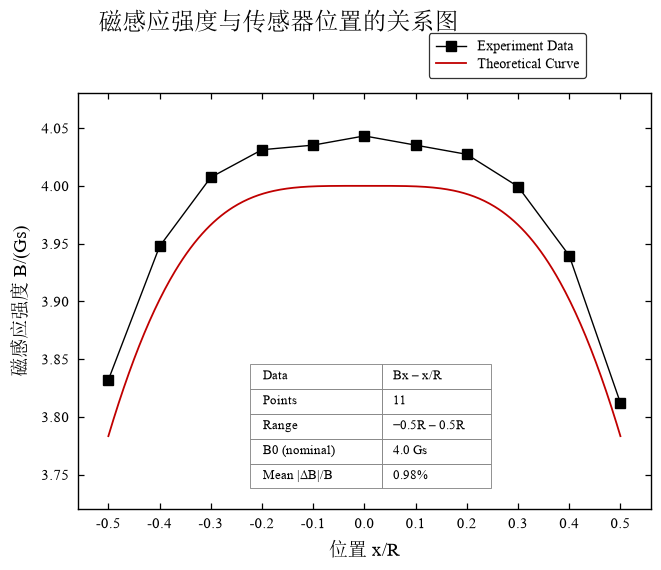

In [2]:
# ================= 图 3：轴向磁场分布（散点 + 理论曲线，Origin 版式） =================
fig, ax = plt.subplots(figsize=(7.4, 5.4))

# 实测曲线（黑色实心方块 + 连线，Line + Symbol）
ax.plot(x_R, B_meas, linestyle='-', linewidth=1.0, marker='s', markersize=6.5,
        color='black', label='Experiment Data', zorder=3)

# 亥姆霍兹线圈轴向场的理论曲线
xx = np.linspace(-0.5, 0.5, 400)
ax.plot(xx, B0 * helmholtz_ratio(xx), color='#C00000', linewidth=1.3,
        label='Theoretical Curve', zorder=2)

style_axes(ax)
ax.set_title('磁感应强度与传感器位置的关系图', fontsize=17, x=0.35, pad=46)

leg = ax.legend(loc='lower left', bbox_to_anchor=(0.60, 1.02),
                fontsize=10, frameon=True, borderpad=0.5,
                labelspacing=0.35, handlelength=2.2)
leg.get_frame().set_linewidth(0.9)
leg.get_frame().set_edgecolor('black')

# ---- Origin 风格数据信息框 ----
add_table_box(ax,
              rows=[['Data',         'Bx – x/R'],
                    ['Points',       f'{len(x_R)}'],
                    ['Range',        '−0.5R – 0.5R'],
                    ['B0 (nominal)', f'{B0:.1f} Gs'],
                    ['Mean |ΔB|/B',  f'{err_pct.mean():.2f}%']],
              col_widths=[0.55, 0.45],
              bbox=[0.30, 0.05, 0.42, 0.30])

plt.savefig('图3_亥姆霍兹线圈_轴向磁场分布.png', dpi=300, bbox_inches='tight')
plt.show()


## 结果分析

**1. 填表结果**

| 位置 x/R | Ux/V | Bx 理论/Gs | Bx 测量/Gs | 相对误差/% |
|---|---|---|---|---|
| −0.5 | 0.968 | 3.784 | 3.832 | 1.27 |
| −0.4 | 0.997 | 3.900 | 3.948 | 1.22 |
| −0.3 | 1.012 | 3.968 | 4.007 | 0.99 |
| −0.2 | 1.018 | 3.992 | 4.031 | 0.98 |
| −0.1 | 1.019 | 4.000 | 4.035 | 0.88 |
| 0 | 1.021 | 4.000 | 4.043 | 1.08 |
| 0.1 | 1.019 | 4.000 | 4.035 | 0.88 |
| 0.2 | 1.017 | 3.992 | 4.027 | 0.88 |
| 0.3 | 1.010 | 3.968 | 3.999 | 0.79 |
| 0.4 | 0.995 | 3.900 | 3.940 | 1.02 |
| 0.5 | 0.963 | 3.784 | 3.812 | 0.74 |

相对误差平均 0.98%，最大 1.27%（$x=-0.5R$），全部在 1.3% 以内。

**2. 轴向磁场分布特点**

- **中心区域高度均匀。** $|x|\le0.2R$ 内，理论值只比中心低 0.2%，实测归一化后低 0.3%–0.4%；
  曲线在中心附近几乎是水平的。这是亥姆霍兹线圈线圈间距等于半径时，
  两线圈磁场的二阶导数 $\mathrm{d}^2B/\mathrm{d}x^2$ 在中心相互抵消的结果，
  所以中心附近磁场既均匀又变化平缓。
- **两侧对称下降。** 曲线关于 $x=0$ 对称；实测 $+0.5R$ 与 $-0.5R$ 处分别为
  3.812、3.832 Gs，相差 0.5%，属于转台定位与线圈不一致带来的小不对称。
- **边缘场强下降。** 到 $x=\pm0.5R$（线圈所在平面）时，理论值降到 $0.946B_0$，
  即比中心低 5.4%；实测归一化值低 5.2%–5.7%，与理论一致。
  曲线在边缘处明显向下弯，说明"均匀场"只存在于中心附近区域。

**3. 误差讨论**

- 实测绝对场强整体比理论值高约 1%，但**归一化后形状与理论的最大偏差只有 0.33%**。
  说明这 1% 是把 $U$ 换算成 $B$ 时的比例误差：标定斜率 $b$ 的误差、
  线圈电流的实际值与标称值之差、以及 $B_0$ 取标称 4 Gs 而非实测值。
  它不改变磁场分布的形状，符合"理论曲线描述相对分布"的定位。
- 若不计截距按 $B=U/b$ 换算，所有点会再高约 0.026 Gs（中心 4.069 Gs），
  可见截距只有约 0.65% 的影响，与表 11-1 中截距不显著异于零的结论一致。
- 中心处实测 4.043 Gs 与标准 4 Gs 相差 1.1%，主要来自激励电流的设定值与标称值的差别。

**4. 结论**

实测轴向磁场随位置的变化曲线与亥姆霍兹线圈的理论分布吻合（归一化形状偏差 $<0.4\%$），
中心 $|x|\le0.2R$ 范围内磁场基本均匀，往两侧对称下降、在线圈平面处约降低 5.4%，
体现了亥姆霍兹线圈"中心区域产生均匀磁场"的特点。
